In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import re
pd.set_option("display.max_columns", None)   
pd.set_option("display.max_rows",None)      
pd.set_option("display.width", None)    

# 1.Loading Dataset

In [2]:
df = pd.read_csv("DataCoSupplyChainDataset.csv", encoding="latin1")

# 2.Data Understanding

In [3]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


# 3.Data Inspection

In [4]:
df.shape

(180519, 53)

In [5]:
df.info()

In [6]:
df.isnull().sum()

In [7]:
df.describe()

In [8]:
df.columns

# 4.Data Cleaning

In [9]:
df.columns = [re.sub(r"[^a-z0-9]+", "_", c.strip().lower()).strip("_") for c in df.columns]
df = df.rename(columns={
    "order_date_dateorders": "order_date",
    "shipping_date_dateorders": "shipping_date",
    "days_for_shipping_real": "days_shipped_real",
    "days_for_shipment_scheduled": "days_shipped_scheduled",
})

In [10]:
drop_cols = [
    # duplicates (verify with np.allclose before dropping)
    "benefit_per_order", "sales_per_customer",
    # PII / masked
    "customer_email", "customer_password", "customer_fname", "customer_lname", "customer_street",
    # empty / no analytical value
    "product_description", "product_image", "order_zipcode",
    # same as another ID column
    "order_customer_id", "order_item_cardprod_id", "product_category_id",
    # IDs, geography and attributes not used in the analysis
    "category_id", "department_id", "product_card_id",
    "customer_zipcode", "customer_state", "order_state", "latitude", "longitude",
    "market", "type", "product_status", "order_item_quantity"]
df = df.drop(columns=[c for c in drop_cols if c in df.columns])
print("Final shape:", df.shape)

Final shape: (180519, 28)


In [11]:
# --- 2.3 Dates
df["order_date"] = pd.to_datetime(df["order_date"], format="%m/%d/%Y %H:%M", errors="coerce")
df["shipping_date"] = pd.to_datetime(df["shipping_date"], format="%m/%d/%Y %H:%M", errors="coerce")
 
# --- 2.4 Text columns: trim spaces, standardise case
for c in df.select_dtypes(include=["object", "string"]).columns:
    df[c] = df[c].astype("string").str.strip()
df["order_status"] = df["order_status"].str.upper()
 
# --- 2.5 Known value fixes
df["customer_country"] = df["customer_country"].replace({"EE. UU.": "United States"})
df["order_country"] = df["order_country"].replace({"EE. UU.": "United States"})

# --- 2.6 Duplicates (one row per order item)
before = len(df)
df = df.drop_duplicates(subset=["order_item_id"])
print("Duplicate order items dropped:", before - len(df))

Duplicate order items dropped: 0


# 5.FEATURE ENGINEERING

In [12]:
#  Time
df["order_year"] = df["order_date"].dt.year
df["order_month"] = df["order_date"].dt.month
df["order_ym"] = df["order_date"].dt.to_period("M").dt.to_timestamp()
df["order_quarter"] = df["order_date"].dt.quarter
df["order_dow"] = df["order_date"].dt.day_name()
df["order_is_weekend"] = df["order_date"].dt.dayofweek >= 5
df["order_hour"] = df["order_date"].dt.hour
 
# 5.2 Delivery outcome (3-way so cancellations don't count as "not late")
df["delay_days"] = df["days_shipped_real"] - df["days_shipped_scheduled"]
df["delivery_outcome"] = np.select(
    [df["delivery_status"].eq("Shipping canceled"),
     df["delivery_status"].eq("Late delivery")],
    ["Canceled", "Late"],
    default="On-Time/Advance",
)
df["is_canceled"] = df["delivery_outcome"].eq("Canceled")
df["is_late"] = df["delivery_outcome"].eq("Late")
df["is_late_eligible"] = ~df["is_canceled"]       
 
df["order_to_ship_days"] = (df["shipping_date"] - df["order_date"]).dt.total_seconds() / 86400
df["delay_band"] = pd.cut(
    df["delay_days"],
    bins=[-np.inf, -1, 0, 1, 2, np.inf],
    labels=["Early", "On schedule", "+1 day", "+2 days", "3+ days"],
).astype("string")
 
# 4.3 Money
df["profit_margin"] = np.where(df["sales"] > 0, df["order_profit_per_order"] / df["sales"], np.nan)
df["is_loss_making"] = df["order_profit_per_order"] < 0
df["loss_amount"] = np.where(df["is_loss_making"], -df["order_profit_per_order"], 0.0)

# Geography (customer location vs order destination)
df["is_domestic"] = df["customer_country"].eq(df["order_country"])
 
print("\nFinal shape:", df.shape)



Final shape: (180519, 46)


# 6. Analysis

In [14]:
# delivery rate 
late_rate=round((df["late_delivery_risk"].sum()/df["late_delivery_risk"].count())*100,1)
print(f"late_rate = {late_rate}%")

late_rate = 54.8%


In [15]:
N=len(df)

In [16]:
check = pd.crosstab(df["late_delivery_risk"], df["delay_days"] > 0, margins=True)
check.columns = ["delay<=0", "delay>0", "Total"]
display(check)

,delay<=0,delay>0,Total
late_delivery_risk,,,
0,77119,4423,81542
1,0,98977,98977
All,77119,103400,180519


In [17]:
print(df.groupby(["delivery_status", "delivery_outcome"]).size())
print("\nis_canceled vs outcome:")
print(pd.crosstab(df["is_canceled"], df["delivery_outcome"]))
print("\nlate_delivery_risk on canceled orders:\n", df.loc[df["is_canceled"], "late_delivery_risk"].value_counts())

delivery_status    delivery_outcome
Advance shipping   On-Time/Advance     41592
Late delivery      Late                98977
Shipping canceled  Canceled             7754
Shipping on time   On-Time/Advance     32196
dtype: int64

is_canceled vs outcome:
delivery_outcome  Canceled   Late  On-Time/Advance
is_canceled                                       
False                    0  98977            73788
True                  7754      0                0

late_delivery_risk on canceled orders:
 late_delivery_risk
0    7754
Name: count, dtype: int64


In [18]:
print("\nis_canceled vs outcome:")
print(pd.crosstab(df["is_canceled"], df["delivery_outcome"]))


is_canceled vs outcome:
delivery_outcome  Canceled   Late  On-Time/Advance
is_canceled                                       
False                    0  98977            73788
True                  7754      0                0


In [19]:
q1_3 = df["delivery_outcome"].value_counts().to_frame("orders")
q1_3["rate"] = q1_3["orders"] / N          # denominator = ALL orders
display(q1_3.style.format({"orders": "{:,}", "rate": "{:.1%}"}))
print(f"Total orders: {N:,} | Avg delay days: {df['delay_days'].mean():.2f}")

,orders,rate
delivery_outcome,,
Late,"98,977",54.8%
On-Time/Advance,"73,788",40.9%
Canceled,"7,754",4.3%


Total orders: 180,519 | Avg delay days: 0.57


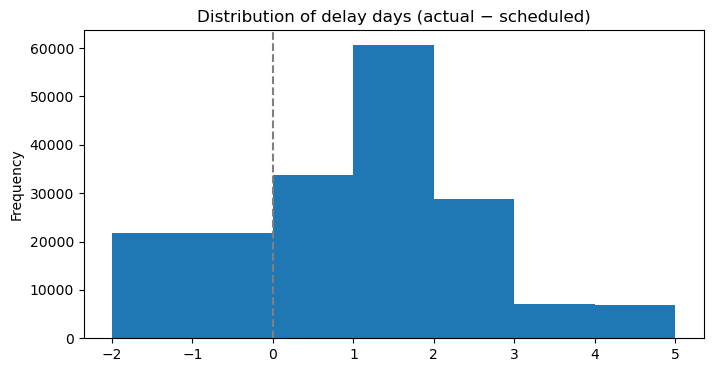

In [20]:
ax = df["delay_days"].plot.hist(bins=range(int(df.delay_days.min()), int(df.delay_days.max()) + 2),
                     figsize=(8, 4), title="Distribution of delay days (actual − scheduled)")
ax.axvline(0, c="grey", ls="--")

In [21]:
display(df.groupby("order_region")
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"), avg_delay=("delay_days", "mean"))
          .query("orders >= 30")
          .assign(gap_vs_avg=lambda t: t.late_rate - df["is_late"].mean())
          .sort_values("late_rate", ascending=False).round(3))

,orders,late_rate,avg_delay,gap_vs_avg
order_region,,,,
Central Africa,1677,0.580,0.640,0.031
South Asia,7731,0.563,0.597,0.014
East Africa,1852,0.559,0.571,0.011
Western Europe,27109,0.558,0.597,0.010
South of USA,4045,0.558,0.580,0.009
Eastern Europe,3920,0.557,0.580,0.008
East of USA,6915,0.557,0.585,0.008
Southeast Asia,9539,0.555,0.558,0.007
Central Asia,553,0.553,0.646,0.005


In [22]:
t = (df.groupby("order_country")
       .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"), avg_delay=("delay_days", "mean"))
       .query("orders >= 30")
       .assign(gap_vs_avg=lambda t: t.late_rate - df["is_late"].mean())
       .sort_values("orders", ascending=False).head(15))
display(t.sort_values("late_rate", ascending=False).round(3))

,orders,late_rate,avg_delay,gap_vs_avg
order_country,,,,
Alemania,9564,0.563,0.593,0.015
El Salvador,3726,0.561,0.619,0.013
India,4783,0.561,0.616,0.013
España,3868,0.557,0.560,0.009
Francia,13222,0.555,0.596,0.007
Indonesia,4204,0.554,0.580,0.005
República Dominicana,3669,0.551,0.596,0.002
Estados Unidos,24840,0.550,0.576,0.002
México,13172,0.550,0.593,0.002


In [23]:
for col, n in [("order_region", 20), ("order_country", 10)]:
    print(f"\n=== {col} ===")
    display(df.groupby(col)
              .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
              .query("orders >= 30")
              .assign(priority_risk=lambda t: t.late_rate * t.orders)
              .sort_values("priority_risk", ascending=False).head(n).round(3))


=== order_region ===


,orders,late_rate,priority_risk
order_region,,,
Central America,28341,0.548,15518.0
Western Europe,27109,0.558,15140.0
South America,14935,0.543,8111.0
Oceania,10148,0.540,5482.0
Southeast Asia,9539,0.555,5297.0
Northern Europe,9792,0.540,5292.0
Southern Europe,9431,0.544,5129.0
Caribbean,8318,0.531,4415.0
South Asia,7731,0.563,4350.0



=== order_country ===


,orders,late_rate,priority_risk
order_country,,,
Estados Unidos,24840,0.550,13670.0
Francia,13222,0.555,7341.0
México,13172,0.550,7246.0
Alemania,9564,0.563,5383.0
Australia,8497,0.543,4613.0
Brasil,7987,0.542,4331.0
Reino Unido,7302,0.535,3903.0
China,5758,0.542,3123.0
India,4783,0.561,2684.0


In [24]:
avg=late_rate
rate = df.pivot_table(index="order_region", columns="shipping_mode", values="is_late", aggfunc="mean")
display(rate.style.background_gradient(cmap="RdYlBu_r", axis=None, vmin=avg - 0.35, vmax=avg + 0.35).format("{:.1%}"))
 

shipping_mode,First Class,Same Day,Second Class,Standard Class
order_region,,,,
Canada,92.4%,21.2%,75.3%,28.8%
Caribbean,94.9%,49.7%,78.3%,35.3%
Central Africa,92.7%,30.4%,81.1%,42.9%
Central America,95.5%,45.7%,75.0%,38.5%
Central Asia,100.0%,20.3%,86.3%,41.7%
East Africa,98.9%,41.8%,77.1%,39.5%
East of USA,96.4%,47.8%,74.8%,39.8%
Eastern Asia,94.8%,47.5%,79.4%,37.4%
Eastern Europe,96.0%,36.0%,74.9%,39.3%


In [25]:
seg = (df.groupby(["order_region", "shipping_mode"])
         .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
         .query("orders >= 30")
         .assign(priority_risk=lambda t: t.late_rate * t.orders)
         .reset_index())
hv_hr = seg[(seg["orders"] >= seg["orders"].median()) & (seg["late_rate"] > df["is_late"].mean())]
display(hv_hr.sort_values("priority_risk", ascending=False).round(3))

,order_region,shipping_mode,orders,late_rate,priority_risk
90,Western Europe,Second Class,5438,0.779,4236.0
12,Central America,First Class,4382,0.955,4185.0
14,Central America,Second Class,5481,0.750,4111.0
88,Western Europe,First Class,4312,0.952,4107.0
48,South America,First Class,2311,0.932,2154.0
50,South America,Second Class,2827,0.751,2122.0
46,Oceania,Second Class,2035,0.768,1562.0
42,Northern Europe,Second Class,1953,0.762,1489.0
60,Southeast Asia,First Class,1552,0.955,1482.0
68,Southern Europe,First Class,1504,0.972,1462.0


In [26]:
display(df.groupby("department_name")
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
          .query("orders >= 30")
          .assign(gap_vs_avg=lambda t: t.late_rate - df["is_late"].mean())
          .sort_values("late_rate", ascending=False).round(3))

,orders,late_rate,gap_vs_avg
department_name,,,
Pet Shop,492,0.589,0.041
Book Shop,405,0.565,0.017
Health and Beauty,362,0.558,0.010
Fitness,2479,0.555,0.007
Outdoors,9686,0.555,0.007
Technology,1465,0.550,0.002
Golf,33220,0.548,-0.000
Fan Shop,66861,0.548,-0.001
Apparel,48998,0.547,-0.001


In [27]:
display(df.groupby("category_name")
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
          .query("orders >= 30")
          .assign(gap_vs_avg=lambda t: t.late_rate - df["is_late"].mean())
          .sort_values("late_rate", ascending=False).round(3))

,orders,late_rate,gap_vs_avg
category_name,,,
Golf Bags & Carts,61,0.689,0.140
Lacrosse,343,0.601,0.052
Pet Supplies,492,0.589,0.041
Cameras,592,0.581,0.033
Strength Training,111,0.577,0.028
As Seen on TV!,68,0.574,0.025
Music,434,0.571,0.023
Accessories,1780,0.570,0.021
Fitness Accessories,309,0.570,0.021


In [28]:
t = (df.groupby("product_name")
       .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
       .query("orders >= 30")
       .assign(gap_vs_avg=lambda t: t.late_rate - df["is_late"].mean())
       .sort_values("orders", ascending=False).head(15))
display(t.sort_values("late_rate", ascending=False).round(3))

,orders,late_rate,gap_vs_avg
product_name,,,
Adult dog supplies,492,0.589,0.041
Web Camera,592,0.581,0.033
Summer dresses,650,0.565,0.016
Under Armour Girls' Toddler Spine Surge Runni,10617,0.552,0.004
Toys,529,0.550,0.002
Perfect Fitness Perfect Rip Deck,24515,0.550,0.001
Field & Stream Sportsman 16 Gun Fire Safe,17325,0.549,0.001
Pelican Sunstream 100 Kayak,15500,0.548,-0.000
O'Brien Men's Neoprene Life Vest,19298,0.547,-0.001


In [29]:
for col in ["category_name", "product_name"]:
    print(f"\n=== {col} ===")
    display(df.groupby(col)
              .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
              .query("orders >= 30")
              .assign(priority_risk=lambda t: t.late_rate * t.orders)
              .sort_values("priority_risk", ascending=False).head(10).round(3))


=== category_name ===


,orders,late_rate,priority_risk
category_name,,,
Cleats,24551,0.550,13496.0
Men's Footwear,22246,0.545,12121.0
Women's Apparel,21035,0.546,11476.0
Indoor/Outdoor Games,19298,0.547,10565.0
Fishing,17325,0.549,9516.0
Water Sports,15540,0.548,8517.0
Camping & Hiking,13729,0.545,7487.0
Cardio Equipment,12487,0.545,6805.0
Shop By Sport,10984,0.552,6058.0



=== product_name ===


,orders,late_rate,priority_risk
product_name,,,
Perfect Fitness Perfect Rip Deck,24515,0.550,13473.0
Nike Men's CJ Elite 2 TD Football Cleat,22246,0.545,12121.0
Nike Men's Dri-FIT Victory Golf Polo,21035,0.546,11476.0
O'Brien Men's Neoprene Life Vest,19298,0.547,10565.0
Field & Stream Sportsman 16 Gun Fire Safe,17325,0.549,9516.0
Pelican Sunstream 100 Kayak,15500,0.548,8492.0
Diamondback Women's Serene Classic Comfort Bi,13729,0.545,7487.0
Nike Men's Free 5.0+ Running Shoe,12169,0.545,6629.0
Under Armour Girls' Toddler Spine Surge Runni,10617,0.552,5865.0


order_year,2015,2016,2017,2018
order_month,,,,
1,0.541,0.556,0.536,0.563
2,0.549,0.541,0.547,NaN
3,0.548,0.558,0.553,NaN
4,0.538,0.552,0.538,NaN
5,0.551,0.557,0.535,NaN
6,0.541,0.568,0.535,NaN
7,0.555,0.519,0.548,NaN
8,0.557,0.553,0.564,NaN
9,0.567,0.550,0.542,NaN


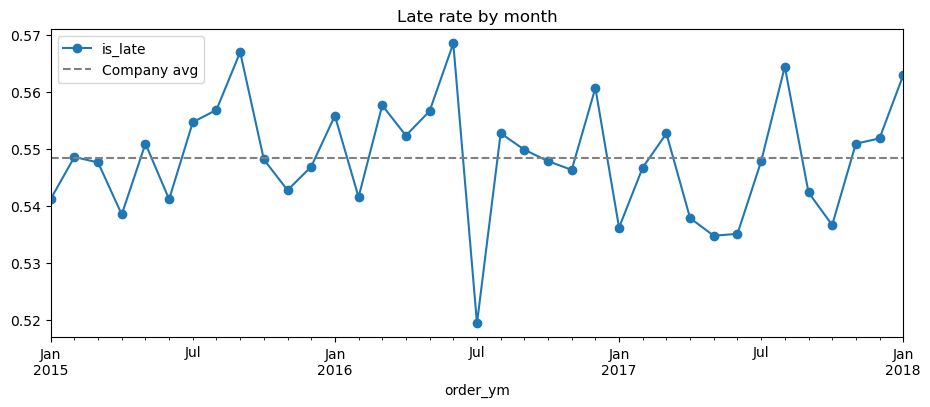

In [30]:
# Trend across the full range: improving, worsening, or seasonal?
monthly = df.groupby("order_ym")["is_late"].mean()
ax = monthly.plot(figsize=(11, 4), marker="o", title="Late rate by month")
ax.axhline(df["is_late"].mean(), ls="--", c="grey", label="Company avg")
ax.legend()

# Seasonality: same calendar month across years
display(df.pivot_table(index="order_month", columns="order_year", values="is_late", aggfunc="mean").round(3))

In [31]:
# Sales and profit on late orders
late = df[df["is_late"]]
print(f"Late orders:           {len(late):,}")
print(f"Sales on late orders:  {late['sales'].sum():,.0f}  ({late['sales'].sum()/df['sales'].sum():.1%} of all sales)")
print(f"Profit on late orders: {late['order_profit_per_order'].sum():,.0f}  "
      f"({late['order_profit_per_order'].sum()/df['order_profit_per_order'].sum():.1%} of all profit)")

Late orders:           98,977
Sales on late orders:  20,126,395  (54.7% of all sales)
Profit on late orders: 2,140,052  (53.9% of all profit)


In [32]:
# Negative-profit late orders (loss exposure)
late = df[df["is_late"]]
neg = late[late["is_loss_making"]]
print(f"Negative-profit late orders: {len(neg):,} ({len(neg)/len(late):.1%} of late orders)")
print(f"Value of those losses:       {neg['loss_amount'].sum():,.0f}")
ontime = df[df["delivery_outcome"] == "On-Time/Advance"]
print(f"For comparison, loss-making share of on-time/advance: {ontime['is_loss_making'].mean():.1%}")

Negative-profit late orders: 18,553 (18.7% of late orders)
Value of those losses:       2,153,627
For comparison, loss-making share of on-time/advance: 18.6%


In [33]:
# Customers affected
late = df[df["is_late"]]
aff, tot = late["customer_id"].nunique(), df["customer_id"].nunique()
print(f"Customers with ≥1 late order: {aff:,} of {tot:,} ({aff/tot:.1%})")
print(f"Customers with 2+ late orders: {(late.groupby('customer_id').size() >= 2).sum():,}")

Customers with ≥1 late order: 16,018 of 20,652 (77.6%)
Customers with 2+ late orders: 10,916


In [34]:
# Late rate by customer segment
display(df.groupby("customer_segment")
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"), customers=("customer_id", "nunique"))
          .assign(gap_vs_avg=lambda t: t.late_rate - df["is_late"].mean())
          .sort_values("late_rate", ascending=False).round(3))

,orders,late_rate,customers,gap_vs_avg
customer_segment,,,,
Home Office,32226,0.551,3718,0.002
Consumer,93504,0.548,10695,-0.000
Corporate,54789,0.547,6239,-0.001


In [35]:
# Late rate by shipping mode, volume-adjusted
display(df.groupby("shipping_mode")
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
          .assign(gap_vs_avg=lambda t: t.late_rate - df["is_late"].mean(),
                  priority_risk=lambda t: t.late_rate * t.orders)
          .sort_values("late_rate", ascending=False).round(3))

,orders,late_rate,gap_vs_avg,priority_risk
shipping_mode,,,,
First Class,27814,0.953,0.405,26513.0
Second Class,35216,0.766,0.218,26987.0
Same Day,9737,0.457,-0.091,4454.0
Standard Class,107752,0.381,-0.168,41023.0


In [36]:
# Average delay days by shipping mode
display(df.groupby("shipping_mode")["delay_days"].agg(["mean", "median", "max"]).round(2))

,mean,median,max
shipping_mode,,,
First Class,1.00,1.0,1
Same Day,0.48,0.0,1
Second Class,1.99,2.0,4
Standard Class,-0.00,0.0,2


,scheduled_days,actual_days
shipping_mode,,
First Class,1.00,2.00
Same Day,0.02,0.50
Second Class,2.00,3.99
Standard Class,4.00,4.00


<Axes: title={'center': 'Scheduled vs actual shipping days'}, xlabel='shipping_mode'>

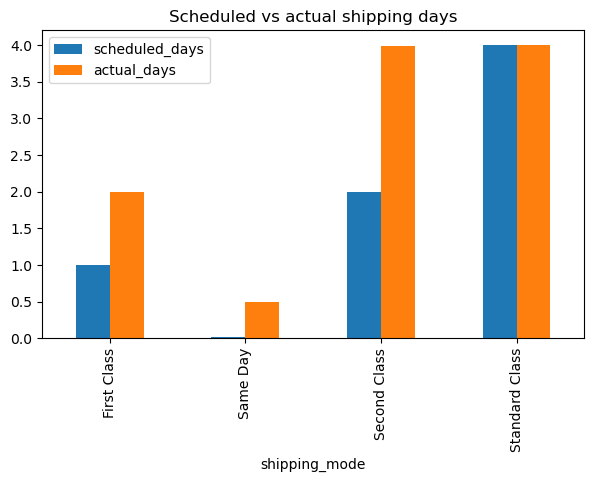

In [37]:
# scheduled = actual − delay
sa = (df.assign(scheduled_days=df["order_to_ship_days"] - df["delay_days"])
        .groupby("shipping_mode")
        .agg(scheduled_days=("scheduled_days", "mean"), actual_days=("order_to_ship_days", "mean"))
        .round(2))
display(sa)
sa.plot.bar(figsize=(7, 4), title="Scheduled vs actual shipping days")

In [38]:
# Which promise breaks? Scheduled vs actual within each mode
display(df.assign(scheduled_days=df["order_to_ship_days"] - df["delay_days"])
          .groupby(["shipping_mode", "scheduled_days"])
          .agg(orders=("is_late", "size"), avg_actual=("order_to_ship_days", "mean"), late_rate=("is_late", "mean"))
          .round(2))

orders  avg_actual  late_rate
shipping_mode  scheduled_days                               
First Class     1.0             27814        2.00       0.95
Same Day       -0.5              4657        0.50       0.96
                0.5              5080        0.50       0.00
Second Class    2.0             35216        3.99       0.77
Standard Class  4.0            107752        4.00       0.38

In [39]:
# Finding: worst mode, gap vs average, probable reason
t = (df.assign(scheduled_days=df["order_to_ship_days"] - df["delay_days"])
       .groupby("shipping_mode")
       .agg(late_rate=("is_late", "mean"), sched=("scheduled_days", "mean"), actual=("order_to_ship_days", "mean"))
       .sort_values("late_rate", ascending=False))
avg = df["is_late"].mean()
w = t.index[0]
print(f"Worst mode: {w}, late rate {t.loc[w, 'late_rate']:.1%} ({(t.loc[w, 'late_rate'] - avg)*100:+.1f} pts vs company {avg:.1%})")
print(f"Promised {t.loc[w, 'sched']:.1f} days vs actual {t.loc[w, 'actual']:.1f} days "
      f"→ likely driver: promise is tighter than operations deliver (inferred, no delay-reason column).")

Worst mode: First Class, late rate 95.3% (+40.5 pts vs company 54.8%)
Promised 1.0 days vs actual 2.0 days → likely driver: promise is tighter than operations deliver (inferred, no delay-reason column).


In [40]:
# Total sales and profit: late vs on-time/advance
display(df[~df["is_canceled"]].groupby("delivery_outcome")
          .agg(orders=("sales", "size"), total_sales=("sales", "sum"),
               total_profit=("order_profit_per_order", "sum")).round(0))

,orders,total_sales,total_profit
delivery_outcome,,,
Late,98977,20126395.0,2140052.0
On-Time/Advance,73788,15088034.0,1666369.0


In [41]:
# Average sales and average profit per order
display(df[~df["is_canceled"]].groupby("delivery_outcome")[["sales", "order_profit_per_order"]].mean().round(2))

,sales,order_profit_per_order
delivery_outcome,,
Late,203.34,21.62
On-Time/Advance,204.48,22.58


In [42]:
# Profit margin
g = df[~df["is_canceled"]].groupby("delivery_outcome")[["sales", "order_profit_per_order"]].sum()
print((g["order_profit_per_order"] / g["sales"]).rename("profit_margin").map("{:.2%}".format))

delivery_outcome
Late               10.63%
On-Time/Advance    11.04%
Name: profit_margin, dtype: object


In [43]:
# Rank categories by Priority Risk and recoverable gain
display(df.groupby("category_name")
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
          .query("orders >= 30")
          .assign(priority_risk=lambda t: t.late_rate * t.orders,
                  excess_late_orders=lambda t: ((t.late_rate - df["is_late"].mean()) * t.orders).clip(lower=0))
          .sort_values("excess_late_orders", ascending=False).head(10).round(3))

,orders,late_rate,priority_risk,excess_late_orders
category_name,,,,
Electronics,3156,0.561,1770.0,39.593
Accessories,1780,0.570,1014.0,38.041
Shop By Sport,10984,0.552,6058.0,35.568
Cleats,24551,0.550,13496.0,34.900
Pet Supplies,492,0.589,290.0,20.241
Cameras,592,0.581,344.0,19.412
Lacrosse,343,0.601,206.0,17.936
Fishing,17325,0.549,9516.0,16.853
Golf Gloves,1070,0.563,602.0,15.328


In [44]:
#  Rank products
display(df.groupby("product_name")
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
          .query("orders >= 30")
          .assign(priority_risk=lambda t: t.late_rate * t.orders,
                  excess_late_orders=lambda t: ((t.late_rate - df["is_late"].mean()) * t.orders).clip(lower=0))
          .sort_values("excess_late_orders", ascending=False).head(10).round(3))

,orders,late_rate,priority_risk,excess_late_orders
product_name,,,,
Under Armour Girls' Toddler Spine Surge Runni,10617,0.552,5865.0,43.791
Perfect Fitness Perfect Rip Deck,24515,0.550,13473.0,31.638
Team Golf St. Louis Cardinals Putter Grip,313,0.629,197.0,25.385
Adult dog supplies,492,0.589,290.0,20.241
Hirzl Women's Soffft Flex Golf Glove,298,0.614,183.0,19.609
Web Camera,592,0.581,344.0,19.412
adidas Men's Germany Black Crest Away Tee,289,0.609,176.0,17.544
Field & Stream Sportsman 16 Gun Fire Safe,17325,0.549,9516.0,16.853
Titleist Pro V1 High Numbers Personalized Gol,292,0.599,175.0,14.899


In [45]:
#  Rank shipping mode × region combinations
display(df.groupby(["shipping_mode", "order_region"])
          .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
          .query("orders >= 30")
          .assign(priority_risk=lambda t: t.late_rate * t.orders,
                  excess_late_orders=lambda t: ((t.late_rate - df["is_late"].mean()) * t.orders).clip(lower=0))
          .sort_values("excess_late_orders", ascending=False).head(10).round(3))

orders  late_rate  priority_risk  \
shipping_mode order_region                                        
First Class   Central America    4382      0.955         4185.0   
              Western Europe     4312      0.952         4107.0   
Second Class  Western Europe     5438      0.779         4236.0   
              Central America    5481      0.750         4111.0   
First Class   South America      2311      0.932         2154.0   
              Southern Europe    1504      0.972         1462.0   
              Southeast Asia     1552      0.955         1482.0   
              Northern Europe    1418      0.960         1361.0   
Second Class  South America      2827      0.751         2122.0   
First Class   South Asia         1283      0.966         1240.0   

                               excess_late_orders  
shipping_mode order_region                         
First Class   Central America            1782.387  
              Western Europe             1742.768  
Second Class  Western Europe             1254.392  
              Central America            1105.815  
First Class   South America               886.899  
              Southern Europe             637.370  
              Southeast Asia              631.052  
              Northern Europe             583.523  
Second Class  South America               571.980  
First Class   South Asia                  536.542

In [46]:
avg = df["is_late"].mean()
rec = (df.groupby(["shipping_mode", "order_region"])
         .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
         .query("orders >= 30"))
avoided = ((rec["late_rate"] - avg) * rec["orders"]).clip(lower=0).sum()
n_late = df["is_late"].sum()
print(f"Late orders avoided (estimate): {avoided:,.0f} = {avoided/n_late:.1%} of all late orders")
print(f"Company late rate would fall from {avg:.1%} to {(n_late - avoided)/len(df):.1%}")

Late orders avoided (estimate): 18,944 = 19.1% of all late orders
Company late rate would fall from 54.8% to 44.3%


In [47]:
rows = []
for col in ["shipping_mode", "order_region", "customer_segment", "category_name",
            "department_name", "order_dow", "order_quarter", "order_is_weekend"]:
    t = df.groupby(col).agg(orders=("is_late", "size"), late_rate=("is_late", "mean")).query("orders >= 30")
    rows.append({"factor": col, "best": t["late_rate"].idxmin(), "best_rate": t["late_rate"].min(),
                 "worst": t["late_rate"].idxmax(), "worst_rate": t["late_rate"].max(),
                 "gap_pts": (t["late_rate"].max() - t["late_rate"].min()) * 100})
display(pd.DataFrame(rows).sort_values("gap_pts", ascending=False).round(3))

,factor,best,best_rate,worst,worst_rate,gap_pts
0,shipping_mode,Standard Class,0.381,First Class,0.953,57.251
3,category_name,Men's Golf Clubs,0.477,Golf Bags & Carts,0.689,21.149
1,order_region,Canada,0.488,Central Africa,0.580,9.160
4,department_name,Discs Shop,0.544,Pet Shop,0.589,4.501
5,order_dow,Tuesday,0.543,Friday,0.552,0.870
6,order_quarter,2,0.546,3,0.550,0.433
2,customer_segment,Corporate,0.547,Home Office,0.551,0.348
7,order_is_weekend,True,0.548,False,0.549,0.104


In [50]:
df_delay=df[df["days_shipped_real"]>df["days_shipped_scheduled"]]
df_delay.head()

,days_shipped_real,days_shipped_scheduled,delivery_status,late_delivery_risk,category_name,customer_city,customer_country,customer_id,customer_segment,department_name,order_city,order_country,order_date,order_id,order_item_discount,order_item_discount_rate,order_item_id,order_item_product_price,order_item_profit_ratio,sales,order_item_total,order_profit_per_order,order_region,order_status,product_name,product_price,shipping_date,shipping_mode,order_year,order_month,order_ym,order_quarter,order_dow,order_is_weekend,order_hour,delay_days,delivery_outcome,is_canceled,is_late,is_late_eligible,order_to_ship_days,delay_band,profit_margin,is_loss_making,loss_amount,is_domestic
1,5,4,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,19492,Consumer,Fitness,Bikaner,India,2018-01-13 12:27:00,75939,16.389999,0.05,179254,327.75,-0.80,327.75,311.359985,-249.089996,South Asia,PENDING,Smart watch,327.75,2018-01-18 12:27:00,Standard Class,2018,1,2018-01-01,1,Saturday,True,12,1,Late,False,True,True,5.0,+1 day,-0.760000,True,249.089996,False
5,6,4,Shipping canceled,0,Sporting Goods,Tonawanda,United States,19488,Consumer,Fitness,Toowoomba,Australia,2018-01-13 11:03:00,75935,32.779999,0.10,179250,327.75,0.06,327.75,294.980011,18.580000,Oceania,CANCELED,Smart watch,327.75,2018-01-19 11:03:00,Standard Class,2018,1,2018-01-01,1,Saturday,True,11,2,Canceled,True,False,False,6.0,+2 days,0.056690,False,0.000000,False
6,2,1,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,19487,Home Office,Fitness,Guangzhou,China,2018-01-13 10:42:00,75934,39.330002,0.12,179249,327.75,0.33,327.75,288.420013,95.180000,Eastern Asia,COMPLETE,Smart watch,327.75,2018-01-15 10:42:00,First Class,2018,1,2018-01-01,1,Saturday,True,10,1,Late,False,True,True,2.0,+1 day,0.290404,False,0.000000,False
7,2,1,Late delivery,1,Sporting Goods,Miami,United States,19486,Corporate,Fitness,Guangzhou,China,2018-01-13 10:21:00,75933,42.610001,0.13,179248,327.75,0.24,327.75,285.140015,68.430000,Eastern Asia,PROCESSING,Smart watch,327.75,2018-01-15 10:21:00,First Class,2018,1,2018-01-01,1,Saturday,True,10,1,Late,False,True,True,2.0,+1 day,0.208787,False,0.000000,False
8,3,2,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,19485,Corporate,Fitness,Guangzhou,China,2018-01-13 10:00:00,75932,49.160000,0.15,179247,327.75,0.48,327.75,278.589996,133.720001,Eastern Asia,CLOSED,Smart watch,327.75,2018-01-16 10:00:00,Second Class,2018,1,2018-01-01,1,Saturday,True,10,1,Late,False,True,True,3.0,+1 day,0.407994,False,0.000000,False


In [51]:
total_delay=df_delay["days_shipped_real"]-df_delay["days_shipped_scheduled"]
total_delay.values.mean()

np.float64(1.6167408123791103)